# GVLiD Grapevine Disease Recognition - Midterm baseline notebook

Covers the Midterm brief: dataset analysis, split, four models (Simple CNN, ResNet-18, MobileNetV3-Small, ConvNeXt-Tiny),
required metrics, efficiency numbers, error analysis and shortcut probes. Run on **Colab free T4** (Runtime > Change runtime type > T4 GPU).

**Run order:** top to bottom. Stop at **section 1** and read the label audit before continuing - it matters.

Everything this notebook reports is computed from your data. Nothing in it is a pre-filled result.

In [1]:
  from google.colab import drive
  drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
!ls /content/drive/MyDrive

'??????'
 00h00m00s-00h24m19s-wrong_way_scout-chunked.ts
'10A13 Sign Up.gdoc'
 11A7
'11A7 - 21.10.2021.gsheet'
'11A7 - 7.12.2021.gsheet'
'11A7 - 9.11.2021.gsheet'
'11A7 - Đào Đức Nghiệp'
'11A7 - Đào Đức Nghiệp - Đề 1.gdoc'
'11ENG13 - WRITING PORTFOLIO - Đào Đức Nghiệp.pdf'
 1200x1200bf-60.jpg
'1888201 Mili - Mortal With You (TV Size).rar'
'2020-2021 G10 Listening _ Speaking Orientation-2.pptx'
 262238315_208144891473365_8226359719340319957_n.jpg
 335428017_965326137805911_1162493397526699524_n.jpg
 4583d8e22a6e2db89e727c71f28a0ec2546c7b23_s2_n2.jpg
'4cwc 2023.gsheet'
'4CWC24 Vietnam Team Scoresheet.gsheet'
'4dci2026 sheet of hell.gsheet'
'600 câu trắc nghiệm lượng giác.pdf'
'8e7af7a3-574c-4c2f-8677-3697f5979012-đã chuyển đổi.pdf'
 a_h_i.gdoc
 AiseesoftScreenRecorder_pass1234.rar
'Ameliorate v1.5.osk'
'ATI Project.gdoc'
 ATI-weekly-tutorial
'Bài tập tiếng Nhật sơ cấp 1.pdf'
'Bài thu hoạch .gdoc'
'Báo cáo Kiểm thử Sprint 1.gsheet'
 bg.png


In [3]:
!ls "/content/drive/MyDrive/DATASET.zip"

/content/drive/MyDrive/DATASET.zip


In [4]:
!unzip -q "/content/drive/MyDrive/DATASET.zip" -d /content/data
!find /content/data -maxdepth 3 -name "metadata.json"

/content/data/A/metadata.json


## 0. Setup

In [5]:
import os, sys, json, time, copy, random, platform, hashlib, shutil, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
warnings.filterwarnings("ignore", category=FutureWarning)

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass  # running locally

# ------------------------- EDIT THESE PATHS -------------------------
# DATA_ROOT must contain the four class folders (Black rot, esca, healthy, leaf blight) and metadata.json
DATA_ROOT = Path("/content/data/A")
OUT       = Path("/content/drive/MyDrive/GVLiD_outputs")   # results are saved here (persistent)
WORK      = Path("/content/work")                                   # local scratch (image cache, checkpoints)
# --------------------------------------------------------------------

SEED, IMG, BATCH = 42, 224, 32
DUP_T = 4            # near-duplicate threshold: max Hamming distance (of 64 bits) between difference-hashes
IMG_EXT = {".jpg", ".jpeg", ".png"}
CLASSES = ["Healthy", "Black Rot", "Esca", "Leaf Blight"]          # class ids 0..3 (same order as the brief)
CLASS2ID = {c: i for i, c in enumerate(CLASSES)}
NC = len(CLASSES)
FOLDER2CLASS = {"healthy": "Healthy", "black rot": "Black Rot", "esca": "Esca", "leaf blight": "Leaf Blight"}
for d in (OUT, OUT / "figures", OUT / "splits", WORK / "ckpt"):
    d.mkdir(parents=True, exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

def load_rgb(path, size=None):
    """Open an image; for JPEGs use draft mode so 1080px images decode fast, then resize to size x size."""
    im = Image.open(path)
    if size:
        im.draft("RGB", (size, size))
    im = im.convert("RGB")
    if size:
        im = im.resize((size, size), Image.BILINEAR)
    return im

def show_grid(paths, titles, ncols=4, size=3, suptitle=""):
    n = len(paths); nrows = max(1, int(np.ceil(n / ncols)))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    for ax, p, t in zip(axes, paths, titles):
        ax.imshow(load_rgb(p, 256)); ax.set_title(t, fontsize=8)
    fig.suptitle(suptitle); plt.tight_layout()
    return fig

seed_everything()
print("Python", sys.version.split()[0], "| root exists:", DATA_ROOT.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Python 3.13.16 | root exists: True


In [6]:
!ls "/content/data/A"

'Black rot'   esca   healthy  'leaf blight'   metadata.json


## 1. Load metadata, locate images, audit the labels

`metadata.json` has one record per image (vineyard, GPS, time, lighting, weather, device, `Disease_Type`).
The class folders give a second source of labels. **We check that the two sources agree before trusting either.**

In [7]:
RENAME = {"Image_ID": "sample_id", "image_filename": "filename", "Disease_Type": "meta_label",
          "Plant_Health_Status": "health_status", "Location.Vineyard": "vineyard",
          "Location.GPS.Latitude": "lat", "Location.GPS.Longitude": "lon",
          "Environmental_Conditions.Time_of_Capture": "time", "Environmental_Conditions.Lighting": "lighting",
          "Environmental_Conditions.Weather": "weather", "Device_Specifications.Device_Name": "device",
          "Device_Specifications.Sensor": "sensor", "Device_Specifications.OS": "os"}
meta = pd.json_normalize(json.load(open(DATA_ROOT / "metadata.json"))).rename(columns=RENAME)
print("metadata rows:", len(meta))

files, clash = {}, 0
for folder in DATA_ROOT.iterdir():
    key = folder.name.lower().strip()
    if folder.is_dir() and key in FOLDER2CLASS:
        for p in folder.rglob("*"):
            if p.suffix.lower() in IMG_EXT:
                clash += p.name in files
                files[p.name] = (p, FOLDER2CLASS[key])
print("images found on disk:", len(files), "| filename clashes across folders:", clash)
meta["path"] = meta.filename.map(lambda f: files[f][0] if f in files else None)
meta["folder_label"] = meta.filename.map(lambda f: files[f][1] if f in files else None)
print("metadata rows without an image:", int(meta.path.isna().sum()),
      "| images without a metadata row:", len(set(files) - set(meta.filename)))
meta = meta[meta.path.notna()].reset_index(drop=True)

print("\nFolder label (rows) vs metadata Disease_Type (columns):")
display(pd.crosstab(meta.folder_label, meta.meta_label))
n_bad = int((meta.folder_label != meta.meta_label).sum())
print(f"\nRows where the two label sources disagree: {n_bad} of {len(meta)}")

metadata rows: 3477
images found on disk: 3477 | filename clashes across folders: 0
metadata rows without an image: 0 | images without a metadata row: 0

Folder label (rows) vs metadata Disease_Type (columns):


meta_label,Black Rot,Esca,Healthy,Leaf Blight
folder_label,,,,
Black Rot,808,0,0,0
Esca,1,887,0,0
Healthy,0,0,438,671
Leaf Blight,0,1,671,0



Rows where the two label sources disagree: 1344 of 3477


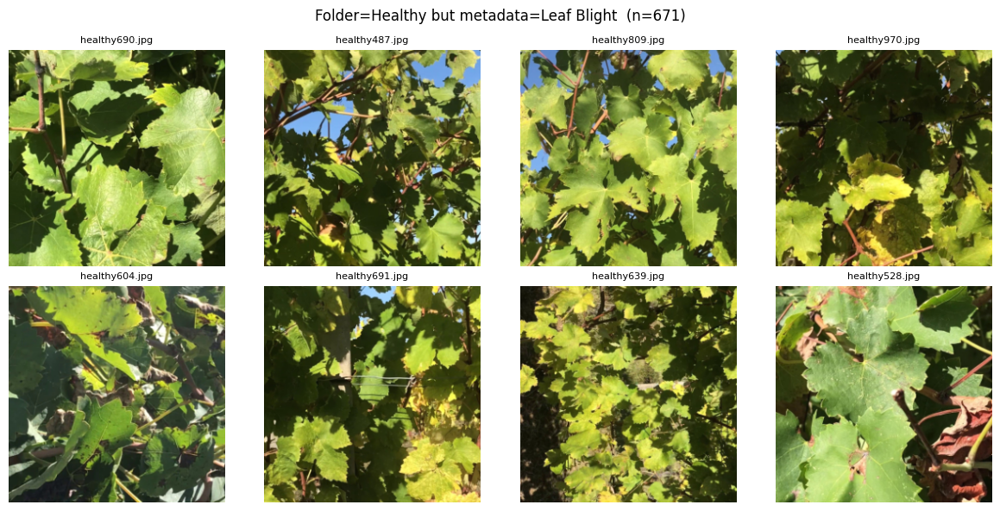

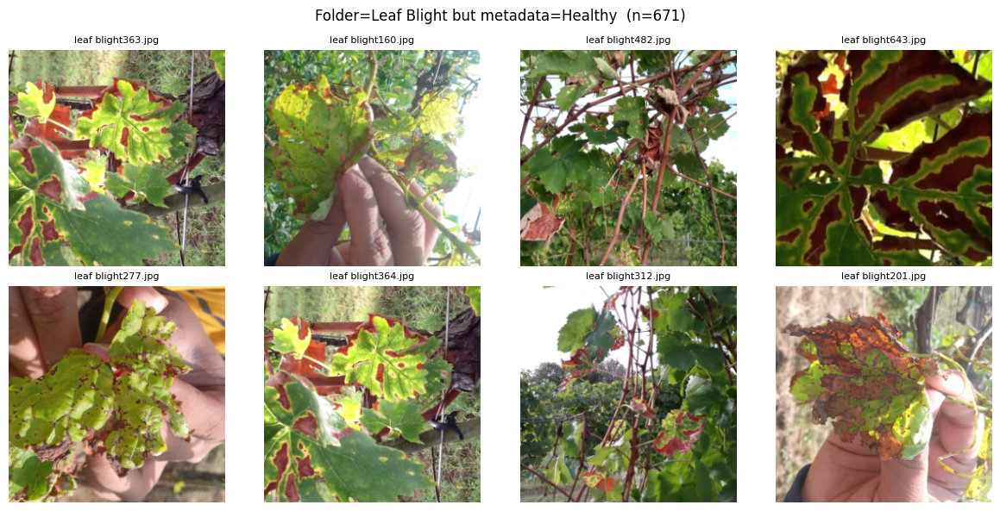

In [8]:
# Look at the images in the disagreeing groups. A healthy leaf has no lesions/necrosis; a leaf-blight leaf does.
rng = np.random.RandomState(SEED)
groups = {
    "Folder=Healthy but metadata=Leaf Blight": meta[(meta.folder_label == "Healthy") & (meta.meta_label == "Leaf Blight")],
    "Folder=Leaf Blight but metadata=Healthy": meta[(meta.folder_label == "Leaf Blight") & (meta.meta_label == "Healthy")],
}
for title, g in groups.items():
    if len(g) == 0:
        print(title, "-> no rows"); continue
    s = g.sample(min(8, len(g)), random_state=SEED)
    fig = show_grid(list(s.path), [f"{r.filename}" for r in s.itertuples()], ncols=4, suptitle=f"{title}  (n={len(g)})")
    fig.savefig(OUT / "figures" / ("label_audit_" + title.split(" but")[0].replace("=", "_").replace(" ", "") + ".png"), dpi=120)
    plt.show()

**Decide which label source is correct.** Look at both grids: do the leaves match the *folder* name or the *metadata* label?
Then set the two variables below. `LABELS_CONFIRMED` stays `False` until you have looked - the notebook refuses to continue otherwise.
Record your decision and evidence (a few example filenames) in the report, in the dataset-analysis section.

In [9]:
LABEL_SOURCE = "folder"      # "folder" = folder the image is stored in | "metadata" = Disease_Type column
LABELS_CONFIRMED = True     # <-- change to True after you inspected the grids above
meta["label"] = meta.folder_label if LABEL_SOURCE == "folder" else meta.meta_label
print("Using labels from:", LABEL_SOURCE)

Using labels from: folder


## 2. Dataset analysis (brief, Section A)

Images: 3477 | imbalance ratio (max/min class): 1.65


,n,share_%
label,,
Healthy,1109,31.9
Black Rot,808,23.2
Esca,888,25.5
Leaf Blight,672,19.3



Metadata fields: ['sample_id', 'filename', 'health_status', 'meta_label', 'vineyard', 'lat', 'lon', 'time', 'lighting', 'weather', 'device', 'sensor', 'os', 'folder_label', 'label']
  device: 1 distinct -> {'Redmi Note 10 5G': 3477}
  sensor: 1 distinct -> {'Sony IMX 582 1/2rr': 3477}
  os: 1 distinct -> {'Android': 3477}
  lighting: 3 distinct -> {'Natural sunlight': 1175, 'Overcast': 1164, 'Partly cloudy': 1138}
  weather: 3 distinct -> {'Windy': 1176, 'Humid': 1160, 'Clear': 1141}
  vineyard: 28 distinct, images per vineyard min/median/max = [107.0, 125.0, 144.0]
  distinct GPS points: 28
  capture dates: 1 distinct (2023-06-15 07:30:00+05:30 -> 2023-06-15 20:00:00+05:30)

!! Only ONE device in the metadata: a device-based OOD split is impossible for the Final.

Image sizes (w,h): {(1080, 1080): 3477}


,variable,chi2_p_value
0,lighting,0.461
1,weather,0.586
2,vineyard,0.158


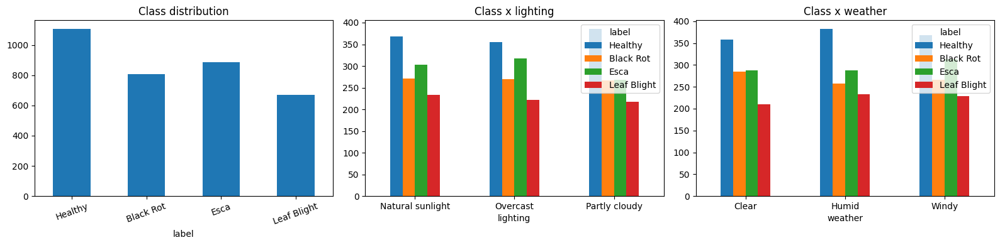

In [10]:
assert LABELS_CONFIRMED, "Set LABELS_CONFIRMED = True in section 1 after checking the label audit."
from scipy.stats import chi2_contingency

# --- counts, imbalance
cnt = meta.label.value_counts().reindex(CLASSES)
summary = pd.DataFrame({"n": cnt, "share_%": (100 * cnt / len(meta)).round(1)})
print("Images:", len(meta), "| imbalance ratio (max/min class):", round(cnt.max() / cnt.min(), 2))
display(summary)

# --- acquisition metadata fields
print("\nMetadata fields:", [c for c in meta.columns if c not in ("path",)])
for col in ["device", "sensor", "os", "lighting", "weather"]:
    print(f"  {col}: {meta[col].nunique()} distinct ->", meta[col].value_counts().to_dict())
print(f"  vineyard: {meta.vineyard.nunique()} distinct, images per vineyard min/median/max =",
      meta.vineyard.value_counts().agg(["min", "median", "max"]).tolist())
print(f"  distinct GPS points: {meta[['lat','lon']].drop_duplicates().shape[0]}")
t = pd.to_datetime(meta.time)
print(f"  capture dates: {t.dt.date.nunique()} distinct ({t.min()} -> {t.max()})")
if meta.device.nunique() < 2:
    print("\n!! Only ONE device in the metadata: a device-based OOD split is impossible for the Final.")

# --- image sizes (header read only)
sizes = Counter(Image.open(p).size for p in meta.path)
print("\nImage sizes (w,h):", dict(sizes.most_common(5)))

# --- is the metadata tied to the class? (chi-square independence; p > 0.05 = no evidence of a link)
rows = []
for col in ["lighting", "weather", "vineyard"]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(meta.label, meta[col]))
    rows.append({"variable": col, "chi2_p_value": round(p, 3)})
display(pd.DataFrame(rows))

# --- figures + tables
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
cnt.plot.bar(ax=axes[0], title="Class distribution", rot=20)
pd.crosstab(meta.lighting, meta.label)[CLASSES].plot.bar(ax=axes[1], title="Class x lighting", rot=0)
pd.crosstab(meta.weather, meta.label)[CLASSES].plot.bar(ax=axes[2], title="Class x weather", rot=0)
plt.tight_layout(); fig.savefig(OUT / "figures" / "dataset_distribution.png", dpi=150); plt.show()
summary.to_csv(OUT / "dataset_summary_classes.csv")
for col in ["lighting", "weather", "vineyard"]:
    pd.crosstab(meta[col], meta.label)[CLASSES].to_csv(OUT / f"dataset_crosstab_{col}.csv")

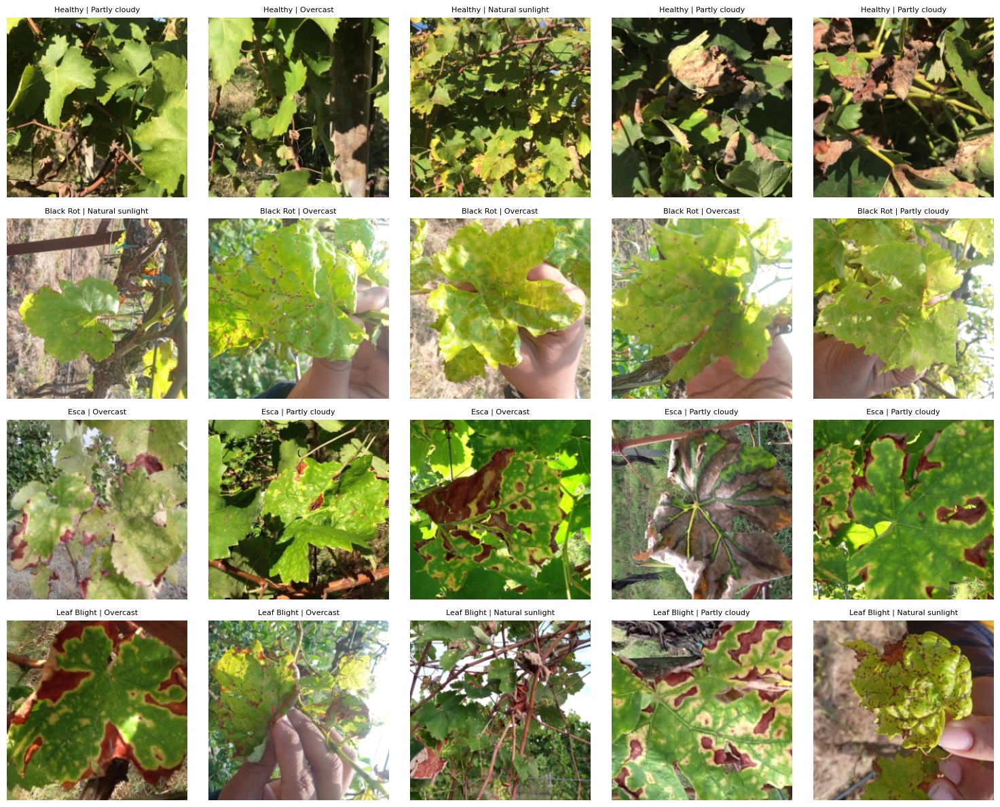

In [11]:
# Representative samples: 5 random images per class
fig, axes = plt.subplots(4, 5, figsize=(15, 12))
for r, c in enumerate(CLASSES):
    s = meta[meta.label == c].sample(5, random_state=SEED)
    for k, row in enumerate(s.itertuples()):
        axes[r, k].imshow(load_rgb(row.path, 256)); axes[r, k].axis("off")
        axes[r, k].set_title(f"{c} | {row.lighting}", fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "figures" / "samples_per_class.png", dpi=120); plt.show()

## 3. Near-duplicate audit and the split

Leaves photographed several times can leak across train/test and inflate scores. We hash every image (64-bit difference hash),
link images whose hashes differ by at most `DUP_T` bits, and keep each linked cluster inside one split (`StratifiedGroupKFold`).
This is a coarse check, so inspect the pairs it finds.

hashing:   0%|          | 0/3477 [00:00<?, ?it/s]

Near-duplicate pairs (distance <= 4): 3731
Clusters with >1 image: 446 covering 1696 images (48.8%) | largest cluster: 16
Clusters mixing different labels: 182 (possible label noise or hash false-positive)


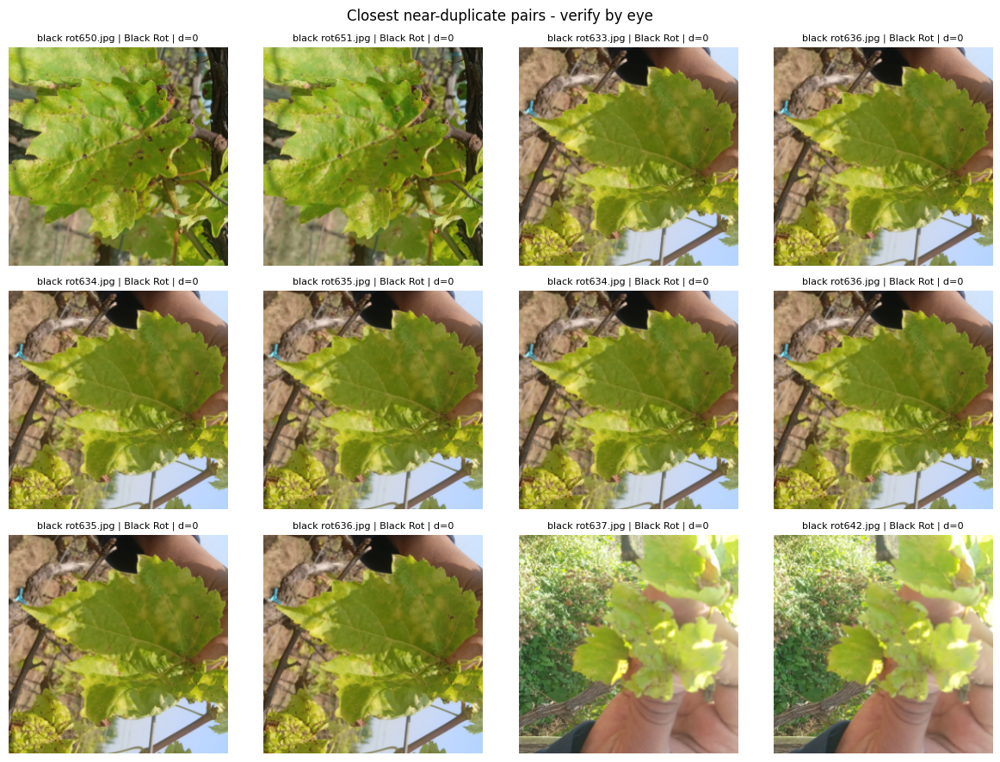

In [12]:
assert LABELS_CONFIRMED
def dhash(path, hs=8):
    im = Image.open(path); im.draft("L", (hs * 8, hs * 8))
    a = np.asarray(im.convert("L").resize((hs + 1, hs), Image.BILINEAR), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).ravel()

H = np.stack([dhash(p) for p in tqdm(meta.path, desc="hashing")]).astype(np.float32)   # N x 64
D = H @ (1 - H).T + (1 - H) @ H.T                                                     # pairwise Hamming distance
np.fill_diagonal(D, 99)

from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
n_comp, comp = connected_components(csr_matrix(D <= DUP_T), directed=False)
meta["cluster"] = comp
sz = pd.Series(comp).value_counts()
multi = sz[sz > 1]
print(f"Near-duplicate pairs (distance <= {DUP_T}): {int(np.triu(D <= DUP_T).sum())}")
print(f"Clusters with >1 image: {len(multi)} covering {int(multi.sum())} images ({100*multi.sum()/len(meta):.1f}%) | largest cluster: {int(sz.max())}")
mixed = meta.groupby("cluster").label.nunique()
print("Clusters mixing different labels:", int((mixed > 1).sum()), "(possible label noise or hash false-positive)")

pairs = np.argwhere(np.triu(D <= DUP_T))
if len(pairs):
    pairs = pairs[np.argsort(D[pairs[:, 0], pairs[:, 1]])][:6]
    paths, titles = [], []
    for a, b in pairs:
        for k in (a, b):
            paths.append(meta.path[k]); titles.append(f"{meta.filename[k]} | {meta.label[k]} | d={int(D[a,b])}")
    show_grid(paths, titles, ncols=4, suptitle="Closest near-duplicate pairs - verify by eye")
    plt.savefig(OUT / "figures" / "near_duplicate_pairs.png", dpi=120); plt.show()

**Hotfix - tighter duplicate clustering.** The audit above links images by hash distance only, so it chained unrelated leaves (182 clusters mixed different labels, ~49% of images flagged). Genuine duplicates always share a label, so the cells below only link same-label images. First compare thresholds in the table, then set `DUP_T` and apply it. Afterwards re-run the split cell and the cache/`idx` cell.

In [13]:
# Hotfix A: compare thresholds, linking only images with the SAME label
lab = meta.label.map(CLASS2ID).to_numpy()
same = lab[:, None] == lab[None, :]
rows = []
for T in (0, 1, 2, 4):
    A = (D <= T) & same
    _, c = connected_components(csr_matrix(A), directed=False)
    sz = pd.Series(c).value_counts(); m = sz[sz > 1]
    rows.append(dict(T=T, same_label_pairs=int(np.triu(A).sum()), cross_label_pairs=int(np.triu((D <= T) & ~same).sum()),
                     clusters=len(m), images_in_clusters=int(m.sum()), pct=round(100 * m.sum() / len(meta), 1), largest=int(sz.max())))
display(pd.DataFrame(rows))

,T,same_label_pairs,cross_label_pairs,clusters,images_in_clusters,pct,largest
0,0,3329,293,446,1512,43.5,16
1,1,3329,381,446,1512,43.5,16
2,2,3333,395,445,1512,43.5,16
3,4,3334,397,446,1514,43.5,16


T=2: 445 clusters with >1 image, covering 1512 images (43.5%), largest cluster = 16


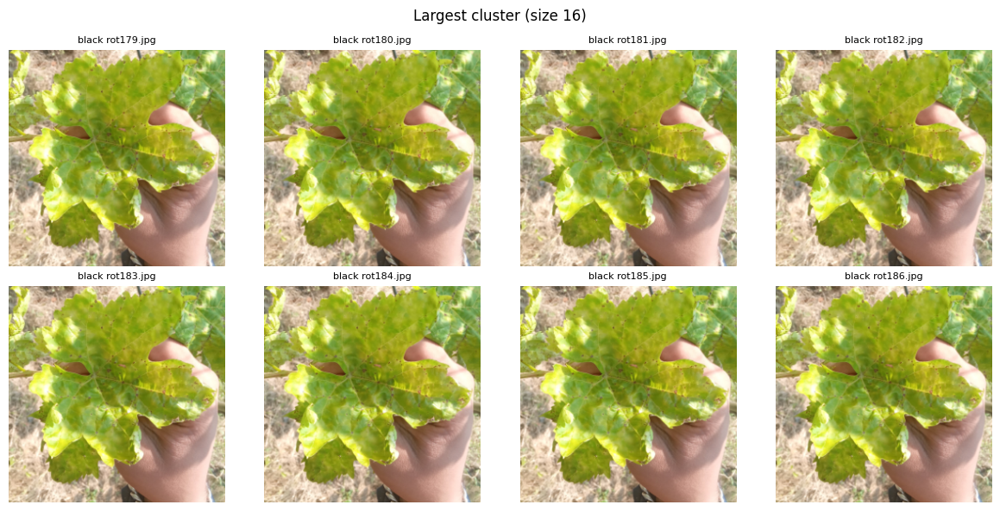

Old split removed. Now re-run: the split cell, then the cache/idx cell (the cache loads instantly).


In [14]:
# Hotfix B: apply the chosen threshold and rebuild the split from the new clusters
DUP_T = 2        # <- choose from the table above (smaller = stricter)
lab = meta.label.map(CLASS2ID).to_numpy()
same = lab[:, None] == lab[None, :]
_, comp = connected_components(csr_matrix((D <= DUP_T) & same), directed=False)
meta["cluster"] = comp
sz = pd.Series(comp).value_counts(); multi = sz[sz > 1]
print(f"T={DUP_T}: {len(multi)} clusters with >1 image, covering {int(multi.sum())} images "
      f"({100 * multi.sum() / len(meta):.1f}%), largest cluster = {int(sz.max())}")
assert (meta.groupby("cluster").label.nunique() == 1).all()

# eyeball the largest cluster: every image should show the same leaf / scene
big = meta[meta.cluster == sz.index[0]].head(8)
show_grid(list(big.path), list(big.filename), ncols=4, suptitle=f"Largest cluster (size {int(sz.iloc[0])})")
plt.show()

# the old split file was built from the loose clusters -> delete it so the split cell rebuilds it
(OUT / "splits" / f"iid_split_{LABEL_SOURCE}_seed{SEED}.csv").unlink(missing_ok=True)
meta = meta.drop(columns=["split"], errors="ignore")
print("Old split removed. Now re-run: the split cell, then the cache/idx cell (the cache loads instantly).")

In [15]:
from sklearn.model_selection import StratifiedGroupKFold
SPLIT_FILE = OUT / "splits" / f"iid_split_{LABEL_SOURCE}_seed{SEED}.csv"
if SPLIT_FILE.exists():                       # the Final needs this exact split, so never silently recompute it
    sp = pd.read_csv(SPLIT_FILE)
    meta = meta.merge(sp[["sample_id", "split"]], on="sample_id", how="left")
    assert meta.split.notna().all(), "split file does not cover all samples"
    print("Loaded existing split:", SPLIT_FILE.name)
else:
    yy = meta.label.map(CLASS2ID).values
    sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)       # 7 folds -> ~14% each
    folds = [te for _, te in sgkf.split(np.zeros(len(yy)), yy, groups=meta.cluster.values)]
    meta["split"] = "train"
    meta.loc[folds[0], "split"] = "test"
    meta.loc[folds[1], "split"] = "val"
    meta[["sample_id", "filename", "label", "split", "cluster", "vineyard", "lighting", "weather"]].to_csv(SPLIT_FILE, index=False)
    print("Created split:", SPLIT_FILE.name)

assert (meta.groupby("cluster").split.nunique() == 1).all(), "a duplicate cluster spans several splits"
tab = pd.crosstab(meta.split, meta.label)[CLASSES].loc[["train", "val", "test"]]
tab["total"] = tab.sum(1); tab["share_%"] = (100 * tab.total / len(meta)).round(1)
display(tab); tab.to_csv(OUT / "split_summary.csv")

Created split: iid_split_folder_seed42.csv


label,Healthy,Black Rot,Esca,Leaf Blight,total,share_%
split,,,,,,
train,788,592,635,478,2493,71.7
val,161,112,126,98,497,14.3
test,160,104,127,96,487,14.0


## 4. Cache resized images (one-off, ~1-3 min) and sanity-check the lighting metadata

In [16]:
from concurrent.futures import ThreadPoolExecutor
key = hashlib.md5("|".join(meta.filename).encode()).hexdigest()[:8]
CACHE = WORK / f"X{IMG}_{len(meta)}_{key}.npy"
if CACHE.exists():
    X = np.load(CACHE)
else:
    with ThreadPoolExecutor(8) as ex:
        X = np.stack(list(tqdm(ex.map(lambda p: np.asarray(load_rgb(p, IMG), dtype=np.uint8), meta.path), total=len(meta))))
    np.save(CACHE, X)
print("cache:", X.shape, X.dtype, f"{X.nbytes/1e6:.0f} MB")

y = meta.label.map(CLASS2ID).values
idx = {s: np.where(meta.split == s)[0] for s in ["train", "val", "test"]}
print({k: len(v) for k, v in idx.items()})

# Does the recorded 'lighting' correspond to actual image brightness? (matters if you build a lighting-based OOD split)
from scipy.stats import f_oneway
meta["brightness"] = X.reshape(len(X), -1).mean(1)
display(meta.groupby("lighting").brightness.agg(["mean", "std", "count"]).round(2))
print("ANOVA p-value (brightness ~ lighting):", round(f_oneway(*[g.brightness.values for _, g in meta.groupby("lighting")]).pvalue, 4))

  0%|          | 0/3477 [00:00<?, ?it/s]

cache: (3477, 224, 224, 3) uint8 523 MB
{'train': 2493, 'val': 497, 'test': 487}


,mean,std,count
lighting,,,
Natural sunlight,107.55,18.92,1175
Overcast,107.94,18.87,1164
Partly cloudy,108.17,19.04,1138


ANOVA p-value (brightness ~ lighting): 0.7242


## 4b. Remove duplicate images from the TRAINING set (review feedback)

The mid-term review pointed out that ~1k of the 3,477 images are repeats. This cell keeps **one random image per duplicate-cluster in the train split only**. Validation, test and the saved split file are untouched, so results stay comparable with the first run.

Important side effect (see the table it prints): the repeats are almost all Black Rot and Leaf Blight, so de-duplication removes most Black Rot training images. That is why the loss is class-weighted here. Outputs go to a separate `*_dedup` folder; the first run is not overwritten.

In [17]:
# ---- De-duplicate the TRAINING set (feedback from the mid-term review) ----
DEDUP_TRAIN    = True   # keep one random image per duplicate-cluster, train split only
CLASS_WEIGHTED = True   # re-weight the loss: de-dup leaves very few Black Rot scenes

idx_train_full = idx["train"].copy()
if DEDUP_TRAIN:
    tr = meta.iloc[idx_train_full]
    keep = tr.groupby("cluster").sample(n=1, random_state=SEED).index.to_numpy()
    idx["train"] = np.sort(keep)
assert set(meta.split.iloc[idx["train"]]) == {"train"}      # nothing from val/test sneaked in

cnt = np.bincount(y[idx["train"]], minlength=len(CLASSES))
CLASS_W_NP = (len(idx["train"]) / (len(CLASSES) * cnt)).astype(np.float32) if CLASS_WEIGHTED else None
tab = pd.DataFrame({"train_before": np.bincount(y[idx_train_full], minlength=len(CLASSES)), "train_after": cnt}, index=CLASSES)
if CLASS_W_NP is not None:
    tab["loss_weight"] = CLASS_W_NP.round(2)
display(tab)
print("train images:", len(idx_train_full), "->", len(idx["train"]))

# outputs of this run go to a separate folder so the first run is not overwritten
OUT = Path(str(OUT) + ("_dedup" if DEDUP_TRAIN else "_v2"))
for d in (OUT, OUT / "figures", OUT / "splits"):
    d.mkdir(parents=True, exist_ok=True)
meta.iloc[idx["train"]][["sample_id", "filename", "label", "cluster"]].to_csv(OUT / "splits" / "train_dedup_ids.csv", index=False)
print("outputs ->", OUT)


,train_before,train_after,loss_weight
Healthy,788,779,0.55
Black Rot,592,72,5.98
Esca,635,635,0.68
Leaf Blight,478,236,1.82


train images: 2493 -> 1722
outputs -> /content/drive/MyDrive/GVLiD_outputs_dedup


**Extra check - camera model from the image files (EXIF).** The brief says two phone sensors, but `metadata.json` lists one device. If the JPEGs still carry EXIF data, this shows how many camera models really appear. Read the result before choosing the Final OOD variable.

In [18]:
def exif_info(p):
    try:
        ex = Image.open(p).getexif()
        sub = ex.get_ifd(0x8769)
        return dict(make=ex.get(271), model=ex.get(272), datetime=sub.get(36867) or ex.get(306))
    except Exception:
        return dict(make=None, model=None, datetime=None)

E = pd.DataFrame([exif_info(p) for p in tqdm(meta.path, desc="reading EXIF")])
E.insert(0, "filename", meta.filename.values)
print("images with an EXIF camera model:", int(E.model.notna().sum()), "of", len(E))
display(E.model.value_counts(dropna=False).head(10))
display(E.datetime.dropna().head())
E.to_csv(OUT / "exif_check.csv", index=False)

reading EXIF:   0%|          | 0/3477 [00:00<?, ?it/s]

images with an EXIF camera model: 1084 of 3477


,count
model,
None,2393
SM-A037F,912
M2101K6I,172


,datetime
0,2024:10:27 11:16:49
1,2024:10:27 11:16:49
2,2024:10:27 11:16:49
3,2024:10:27 11:16:49
4,2024:10:27 11:16:49


**EXIF follow-up (step 1).** Does the phone model line up with the disease class? If one phone mostly photographed certain classes, a phone-based domain split would mix up 'new device' with 'new class'. Also shows which time tag the EXIF dates came from.

In [19]:
def exif_info2(p):
    try:
        ex = Image.open(p).getexif(); sub = ex.get_ifd(0x8769)
        return dict(model=ex.get(272), dt_original=sub.get(36867), dt_modified=ex.get(306), software=ex.get(305))
    except Exception:
        return dict(model=None, dt_original=None, dt_modified=None, software=None)

E2 = pd.DataFrame([exif_info2(p) for p in tqdm(meta.path, desc="reading EXIF")])
E2["filename"] = meta.filename.values
E2["label"] = meta.label.values
E2["split"] = meta.split.values
print("EXIF camera model by class (rows = model, columns = class):")
display(pd.crosstab(E2.model.fillna("no EXIF"), E2.label).reindex(columns=CLASSES, fill_value=0))
print("EXIF camera model by split:")
display(pd.crosstab(E2.model.fillna("no EXIF"), E2.split))
print("capture-time tag (DateTimeOriginal) present:", int(E2.dt_original.notna().sum()),
      "| only the 'modified' tag:", int((E2.dt_original.isna() & E2.dt_modified.notna()).sum()))
print("Software tag:"); display(E2.software.value_counts(dropna=False).head())
print("DateTimeOriginal dates:"); display(E2.dt_original.dropna().str[:10].value_counts().head())
print("modified-tag dates:"); display(E2.dt_modified.dropna().str[:10].value_counts().head())
E2.to_csv(OUT / "exif_check_detailed.csv", index=False)

reading EXIF:   0%|          | 0/3477 [00:00<?, ?it/s]

EXIF camera model by class (rows = model, columns = class):


label,Healthy,Black Rot,Esca,Leaf Blight
model,,,,
M2101K6I,0,96,0,76
SM-A037F,0,680,0,232
no EXIF,1109,32,888,364


EXIF camera model by split:


split,test,train,val
model,,,
M2101K6I,26,110,36
SM-A037F,114,684,114
no EXIF,347,1699,347


capture-time tag (DateTimeOriginal) present: 1084 | only the 'modified' tag: 0
Software tag:


,count
software,
None,3477


DateTimeOriginal dates:


,count
dt_original,
2024:10:27,1084


modified-tag dates:


,count
dt_modified,
2024:10:27,1070


In [20]:
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, confusion_matrix

def score(y_true, probs):
    pred = probs.argmax(1)
    return dict(acc=accuracy_score(y_true, pred), macro_f1=f1_score(y_true, pred, average="macro", labels=range(4)), pred=pred)

## 5. Models and training protocol

Same split, same 224x224 input, same flips-only augmentation, same optimiser family (AdamW + cosine schedule) and the same early-stopping rule for all four models.
The best epoch is chosen **on the validation set only**; the test set is evaluated once, after training.
Hyper-parameters below are reasonable defaults and are **not tuned** - say so in the report.

In [21]:
import torch, torch.nn as nn, torch.nn.functional as F, torchvision
from torchvision import models
from torch.utils.flop_counter import FlopCounterMode

device = "cuda" if torch.cuda.is_available() else "cpu"
use_amp = device == "cuda"
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU only - switch the runtime to T4 GPU")

CFG = {   # checkpoints: torchvision IMAGENET1K_V1 weights
    "simple_cnn":         dict(lr=2e-3, wd=1e-4, epochs=40, patience=8, weights="none (from scratch)"),
    "resnet18":           dict(lr=3e-4, wd=1e-2, epochs=20, patience=6, weights="torchvision ResNet18_Weights.IMAGENET1K_V1"),
    "mobilenet_v3_small": dict(lr=5e-4, wd=1e-2, epochs=20, patience=6, weights="torchvision MobileNet_V3_Small_Weights.IMAGENET1K_V1"),
    "convnext_tiny":      dict(lr=1e-4, wd=5e-2, epochs=15, patience=5, weights="torchvision ConvNeXt_Tiny_Weights.IMAGENET1K_V1"),
}
NC = len(CLASSES)

class SimpleCNN(nn.Module):
    def __init__(self, n_classes=NC):
        super().__init__()
        def blk(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True), nn.MaxPool2d(2))
        self.features = nn.Sequential(blk(3, 16), blk(16, 32), blk(32, 64), blk(64, 128), blk(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

def build_model(name):
    if name == "simple_cnn":
        return SimpleCNN()
    if name == "resnet18":
        m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1); m.fc = nn.Linear(m.fc.in_features, NC)
    elif name == "mobilenet_v3_small":
        m = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, NC)
    elif name == "convnext_tiny":
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, NC)
    else:
        raise ValueError(name)
    return m

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_batch(ids, augment=False, Xsrc=None):
    src = X if Xsrc is None else Xsrc
    xb = torch.from_numpy(src[ids]).to(device).permute(0, 3, 1, 2).float().div_(255)
    if augment:                                   # random horizontal / vertical flips only
        m = torch.rand(len(ids), device=device) < 0.5; xb[m] = xb[m].flip(3)
        m = torch.rand(len(ids), device=device) < 0.5; xb[m] = xb[m].flip(2)
    return (xb - MEAN) / STD

@torch.no_grad()
def predict_probs(model, ids, Xsrc=None, bs=64):
    model.eval(); out = []
    for i in range(0, len(ids), bs):
        with torch.autocast(device_type=device, enabled=use_amp):
            lo = model(to_batch(ids[i:i + bs], Xsrc=Xsrc))
        out.append(F.softmax(lo.float(), 1).cpu())
    return torch.cat(out).numpy()

def make_scaler():
    try: return torch.amp.GradScaler("cuda", enabled=use_amp)
    except Exception: return torch.cuda.amp.GradScaler(enabled=use_amp)

def train_model(name):
    cfg = CFG[name]; seed_everything(SEED)
    model = build_model(name).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["epochs"])
    crit, scaler, rng = nn.CrossEntropyLoss(weight=(torch.tensor(globals()['CLASS_W_NP'], device=device) if globals().get('CLASS_W_NP') is not None else None)), make_scaler(), np.random.RandomState(SEED)
    best = dict(f1=-1.0, loss=1e9, epoch=0, state=None); hist, bad = [], 0
    if device == "cuda": torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(1, cfg["epochs"] + 1):
        model.train(); perm = rng.permutation(idx["train"]); tl = 0.0
        for i in range(0, len(perm), BATCH):
            ids = perm[i:i + BATCH]
            if len(ids) < 2: continue                                   # BatchNorm needs >1 sample
            xb, yb = to_batch(ids, augment=True), torch.from_numpy(y[ids]).to(device)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device, enabled=use_amp):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tl += loss.item() * len(ids)
        sched.step()
        pv = predict_probs(model, idx["val"]); yv = y[idx["val"]]
        vloss = F.nll_loss(torch.log(torch.from_numpy(pv).clamp_min(1e-8)), torch.from_numpy(yv)).item()
        sv = score(yv, pv)
        hist.append(dict(epoch=ep, train_loss=tl / len(perm), val_loss=vloss, val_acc=sv["acc"], val_macro_f1=sv["macro_f1"]))
        if sv["macro_f1"] > best["f1"] or (sv["macro_f1"] == best["f1"] and vloss < best["loss"]):
            best.update(f1=sv["macro_f1"], loss=vloss, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
        print(f"  [{name}] ep {ep:02d} train_loss {tl/len(perm):.3f} | val_loss {vloss:.3f} val_acc {sv['acc']:.3f} val_macroF1 {sv['macro_f1']:.3f}" + (" *" if bad == 0 else ""))
        if bad >= cfg["patience"]: break
    if device == "cuda": torch.cuda.synchronize()
    info = dict(train_time_s=time.perf_counter() - t0, epochs_run=ep, best_epoch=best["epoch"], best_val_macro_f1=best["f1"],
                peak_vram_gb=torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan"))
    model.load_state_dict(best["state"]); torch.save(best["state"], WORK / "ckpt" / f"{name}.pt")
    return model, pd.DataFrame(hist), info

def count_gmacs(model):
    try:
        model.eval(); x = torch.randn(1, 3, IMG, IMG, device=device)
        with FlopCounterMode(display=False) as fc, torch.no_grad(): model(x)
        return fc.get_total_flops() / 2 / 1e9              # FLOPs counted as 2 x MACs
    except Exception as e:
        print("MAC count failed:", e); return float("nan")

@torch.no_grad()
def latency_ms(model, n=100):
    model.eval(); x = torch.randn(1, 3, IMG, IMG, device=device)
    for _ in range(20): model(x)
    if device == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(n): model(x)
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / n * 1000

device: cuda | Tesla T4


## 6. Train and evaluate all four models (about 15-30 min on a T4)

In [22]:
MODELS = list(CFG)
TRAINED, RES, HIST, CM, PRED = {}, [], {}, {}, []
per_class_rows = []
for name in MODELS:
    print(f"\n=== {name} ===")
    model, hist, info = train_model(name)
    TRAINED[name], HIST[name] = model, hist
    yt = y[idx["test"]]; pt = predict_probs(model, idx["test"]); st = score(yt, pt)
    p, r, f, s = precision_recall_fscore_support(yt, st["pred"], labels=range(NC), zero_division=0)
    for c in range(NC):
        per_class_rows.append(dict(model=name, cls=CLASSES[c], precision=p[c], recall=r[c], f1=f[c], support=int(s[c])))
    CM[name] = confusion_matrix(yt, st["pred"], labels=range(NC))
    params = sum(q.numel() for q in model.parameters())
    RES.append(dict(model=name, test_acc=st["acc"], test_macro_f1=st["macro_f1"], **info,
                    params_M=params / 1e6, GMACs=count_gmacs(model), latency_ms_bs1=latency_ms(model)))
    for split in ("val", "test"):
        ii = idx[split]; pr = pt if split == "test" else predict_probs(model, ii)
        d = meta.iloc[ii]
        PRED.append(pd.DataFrame({"sample_id": d.sample_id.values, "true_label": [CLASSES[k] for k in y[ii]],
                                  "pred_label": [CLASSES[k] for k in pr.argmax(1)],
                                  "prob_healthy": pr[:, 0], "prob_black_rot": pr[:, 1], "prob_esca": pr[:, 2], "prob_leaf_blight": pr[:, 3],
                                  "domain_device": d.device.values, "domain_lighting": d.lighting.values,
                                  "domain_weather": d.weather.values, "domain_vineyard": d.vineyard.values,
                                  "model": name, "split": split, "protocol": "iid"}))
    print(f"  TEST acc {st['acc']:.4f} | macro-F1 {st['macro_f1']:.4f}")
results = pd.DataFrame(RES).set_index("model")
per_class = pd.DataFrame(per_class_rows)
display(results.round(4))
results.to_csv(OUT / "results_midterm.csv"); per_class.to_csv(OUT / "results_per_class.csv", index=False)
pd.concat(PRED).to_csv(OUT / "predictions_midterm_iid.csv", index=False)
pd.concat([h.assign(model=m) for m, h in HIST.items()]).to_csv(OUT / "training_history.csv", index=False)
np.save(OUT / "confusion_matrices.npy", np.stack([CM[m] for m in MODELS]))


=== simple_cnn ===
  [simple_cnn] ep 01 train_loss 0.845 | val_loss 0.696 val_acc 0.704 val_macroF1 0.677 *
  [simple_cnn] ep 02 train_loss 0.652 | val_loss 0.770 val_acc 0.660 val_macroF1 0.599
  [simple_cnn] ep 03 train_loss 0.575 | val_loss 0.754 val_acc 0.702 val_macroF1 0.689 *
  [simple_cnn] ep 04 train_loss 0.502 | val_loss 0.446 val_acc 0.791 val_macroF1 0.741 *
  [simple_cnn] ep 05 train_loss 0.514 | val_loss 0.485 val_acc 0.757 val_macroF1 0.735
  [simple_cnn] ep 06 train_loss 0.492 | val_loss 0.563 val_acc 0.777 val_macroF1 0.738
  [simple_cnn] ep 07 train_loss 0.480 | val_loss 0.412 val_acc 0.799 val_macroF1 0.752 *
  [simple_cnn] ep 08 train_loss 0.467 | val_loss 0.438 val_acc 0.789 val_macroF1 0.764 *
  [simple_cnn] ep 09 train_loss 0.449 | val_loss 0.503 val_acc 0.783 val_macroF1 0.761
  [simple_cnn] ep 10 train_loss 0.459 | val_loss 0.394 val_acc 0.795 val_macroF1 0.767 *
  [simple_cnn] ep 11 train_loss 0.406 | val_loss 0.400 val_acc 0.789 val_macroF1 0.713
  [simple_c

100%|██████████| 44.7M/44.7M [00:00<00:00, 188MB/s]


  [resnet18] ep 01 train_loss 0.617 | val_loss 0.689 val_acc 0.797 val_macroF1 0.755 *
  [resnet18] ep 02 train_loss 0.403 | val_loss 0.360 val_acc 0.827 val_macroF1 0.811 *
  [resnet18] ep 03 train_loss 0.329 | val_loss 0.326 val_acc 0.851 val_macroF1 0.824 *
  [resnet18] ep 04 train_loss 0.309 | val_loss 0.308 val_acc 0.835 val_macroF1 0.818
  [resnet18] ep 05 train_loss 0.254 | val_loss 0.342 val_acc 0.835 val_macroF1 0.804
  [resnet18] ep 06 train_loss 0.267 | val_loss 0.451 val_acc 0.829 val_macroF1 0.811
  [resnet18] ep 07 train_loss 0.248 | val_loss 0.380 val_acc 0.827 val_macroF1 0.774
  [resnet18] ep 08 train_loss 0.218 | val_loss 0.368 val_acc 0.827 val_macroF1 0.812
  [resnet18] ep 09 train_loss 0.191 | val_loss 0.412 val_acc 0.815 val_macroF1 0.798
  TEST acc 0.8439 | macro-F1 0.8216

=== mobilenet_v3_small ===
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 134MB/s]


  [mobilenet_v3_small] ep 01 train_loss 0.664 | val_loss 0.682 val_acc 0.744 val_macroF1 0.695 *
  [mobilenet_v3_small] ep 02 train_loss 0.321 | val_loss 0.358 val_acc 0.845 val_macroF1 0.830 *
  [mobilenet_v3_small] ep 03 train_loss 0.306 | val_loss 0.380 val_acc 0.807 val_macroF1 0.778
  [mobilenet_v3_small] ep 04 train_loss 0.248 | val_loss 0.500 val_acc 0.805 val_macroF1 0.792
  [mobilenet_v3_small] ep 05 train_loss 0.213 | val_loss 0.723 val_acc 0.765 val_macroF1 0.747
  [mobilenet_v3_small] ep 06 train_loss 0.202 | val_loss 0.648 val_acc 0.779 val_macroF1 0.758
  [mobilenet_v3_small] ep 07 train_loss 0.188 | val_loss 0.634 val_acc 0.789 val_macroF1 0.765
  [mobilenet_v3_small] ep 08 train_loss 0.180 | val_loss 0.596 val_acc 0.797 val_macroF1 0.776
  TEST acc 0.8234 | macro-F1 0.8107

=== convnext_tiny ===
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 133MB/s]


  [convnext_tiny] ep 01 train_loss 0.614 | val_loss 0.292 val_acc 0.877 val_macroF1 0.849 *
  [convnext_tiny] ep 02 train_loss 0.281 | val_loss 0.334 val_acc 0.851 val_macroF1 0.835
  [convnext_tiny] ep 03 train_loss 0.263 | val_loss 0.324 val_acc 0.853 val_macroF1 0.834
  [convnext_tiny] ep 04 train_loss 0.240 | val_loss 0.281 val_acc 0.847 val_macroF1 0.827
  [convnext_tiny] ep 05 train_loss 0.203 | val_loss 0.281 val_acc 0.843 val_macroF1 0.829
  [convnext_tiny] ep 06 train_loss 0.182 | val_loss 0.342 val_acc 0.823 val_macroF1 0.802
  TEST acc 0.8624 | macro-F1 0.8380


,test_acc,test_macro_f1,train_time_s,epochs_run,best_epoch,best_val_macro_f1,peak_vram_gb,params_M,GMACs,latency_ms_bs1
model,,,,,,,,,,
simple_cnn,0.8563,0.8406,39.4974,32,24,0.8335,0.3851,0.3941,0.2529,0.7277
resnet18,0.8439,0.8216,22.3759,9,3,0.8236,0.6049,11.1786,1.8136,3.0744
mobilenet_v3_small,0.8234,0.8107,24.7408,8,2,0.8300,0.4266,1.5220,0.0555,5.2524
convnext_tiny,0.8624,0.8380,73.1808,6,1,0.8490,2.5188,27.8232,4.4548,5.9209


## 7. Results, confusion matrices and error analysis

model,simple_cnn,resnet18,mobilenet_v3_small,convnext_tiny
per-class F1 (test),,,,
Healthy,0.987,0.984,0.978,0.997
Black Rot,0.867,0.923,0.880,0.950
Esca,0.794,0.760,0.718,0.781
Leaf Blight,0.714,0.619,0.667,0.623


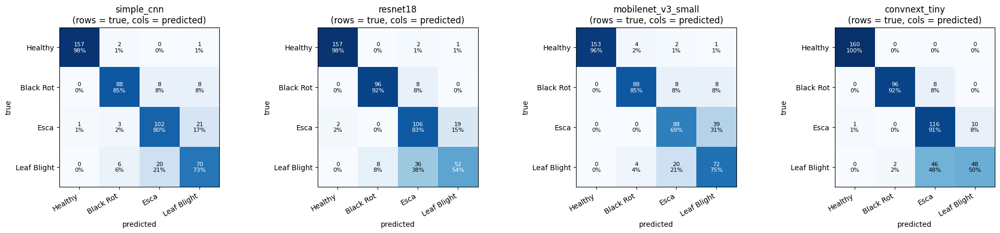

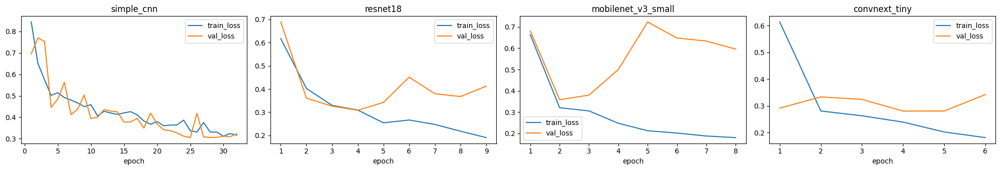

,model,true,predicted_as,count
28,convnext_tiny,Leaf Blight,Esca,46
26,convnext_tiny,Esca,Leaf Blight,10
24,convnext_tiny,Black Rot,Esca,8
21,mobilenet_v3_small,Esca,Leaf Blight,39
23,mobilenet_v3_small,Leaf Blight,Esca,20
19,mobilenet_v3_small,Black Rot,Esca,8
15,resnet18,Leaf Blight,Esca,36
13,resnet18,Esca,Leaf Blight,19
11,resnet18,Black Rot,Esca,8
6,simple_cnn,Esca,Leaf Blight,21


In [23]:
display(per_class.pivot(index="cls", columns="model", values="f1").loc[CLASSES][MODELS].round(3).rename_axis("per-class F1 (test)"))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, m in zip(axes, MODELS):
    cmn = CM[m] / CM[m].sum(1, keepdims=True)
    ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks(range(NC)); ax.set_xticklabels(CLASSES, rotation=30, ha="right"); ax.set_yticks(range(NC)); ax.set_yticklabels(CLASSES)
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, f"{CM[m][i,j]}\n{cmn[i,j]:.0%}", ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > .5 else "black")
    ax.set_title(f"{m}\n(rows = true, cols = predicted)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); fig.savefig(OUT / "figures" / "confusion_matrices.png", dpi=140); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(20, 3.5))
for ax, m in zip(axes, MODELS):
    HIST[m].plot(x="epoch", y=["train_loss", "val_loss"], ax=ax, title=m)
plt.tight_layout(); fig.savefig(OUT / "figures" / "training_curves.png", dpi=120); plt.show()

# most-confused class pairs per model (off-diagonal counts)
rows = []
for m in MODELS:
    for i in range(NC):
        for j in range(NC):
            if i != j and CM[m][i, j] > 0: rows.append((m, CLASSES[i], CLASSES[j], int(CM[m][i, j])))
conf = pd.DataFrame(rows, columns=["model", "true", "predicted_as", "count"]).sort_values(["model", "count"], ascending=[True, False])
display(conf.groupby("model").head(3))

best model on validation: convnext_tiny
67 test errors of 487


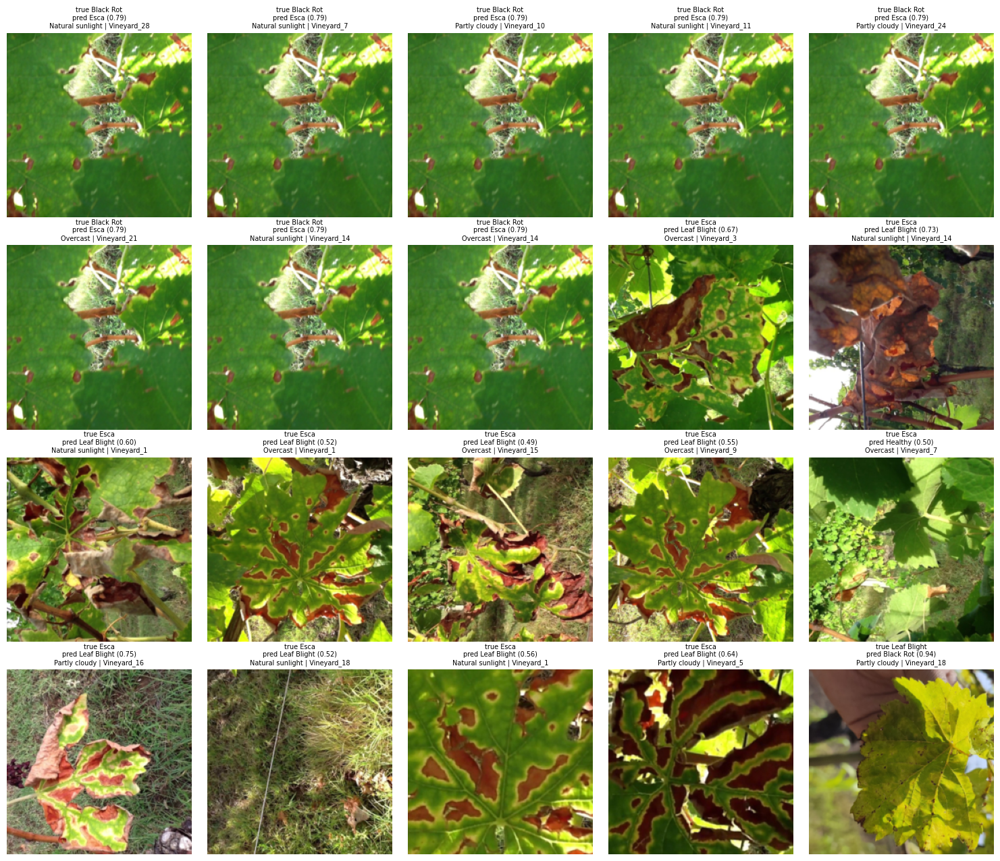

,mean,count
lighting,,
Natural sunlight,0.142,176
Overcast,0.140,157
Partly cloudy,0.130,154


,mean,count
weather,,
Clear,0.132,151
Humid,0.117,163
Windy,0.162,173


In [24]:
# Gallery of test errors of the best model (by validation macro-F1)
best_name = results.best_val_macro_f1.idxmax(); print("best model on validation:", best_name)
pt = predict_probs(TRAINED[best_name], idx["test"]); wrong = np.where(pt.argmax(1) != y[idx["test"]])[0]
print(f"{len(wrong)} test errors of {len(idx['test'])}")
sel = wrong[:min(20, len(wrong))]                                   # the brief asks for >= 20 inspected failures (Final); start here
fig, axes = plt.subplots(int(np.ceil(max(len(sel), 1) / 5)), 5, figsize=(15, 3.2 * int(np.ceil(max(len(sel), 1) / 5))))
for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
for ax, k in zip(np.atleast_1d(axes).ravel(), sel):
    g = idx["test"][k]; ax.imshow(X[g])
    ax.set_title(f"true {CLASSES[y[g]]}\npred {CLASSES[pt[k].argmax()]} ({pt[k].max():.2f})\n{meta.lighting[g]} | {meta.vineyard[g]}", fontsize=7)
plt.tight_layout(); fig.savefig(OUT / "figures" / "error_gallery_best_model.png", dpi=120); plt.show()

# error rate by acquisition slice (small test set -> read with care)
et = pd.DataFrame({"err": (pt.argmax(1) != y[idx["test"]]).astype(int), "lighting": meta.lighting.values[idx["test"]], "weather": meta.weather.values[idx["test"]]})
display(et.groupby("lighting").err.agg(["mean", "count"]).round(3)); display(et.groupby("weather").err.agg(["mean", "count"]).round(3))

**Error audit helper (step 2).** Test images that all four models get wrong, and those where all four give the *same* wrong label (candidates for label noise or very ambiguous images). Uses the trained models from section 6 (still in memory). Look at each image and note what you see.

28 test images are wrong for all four models; 27 of them get the SAME wrong label from all four.


true         predicted  
Black Rot    Esca            8
Esca         Leaf Blight     7
Leaf Blight  Black Rot       2
             Esca           10
Name: n, dtype: int64

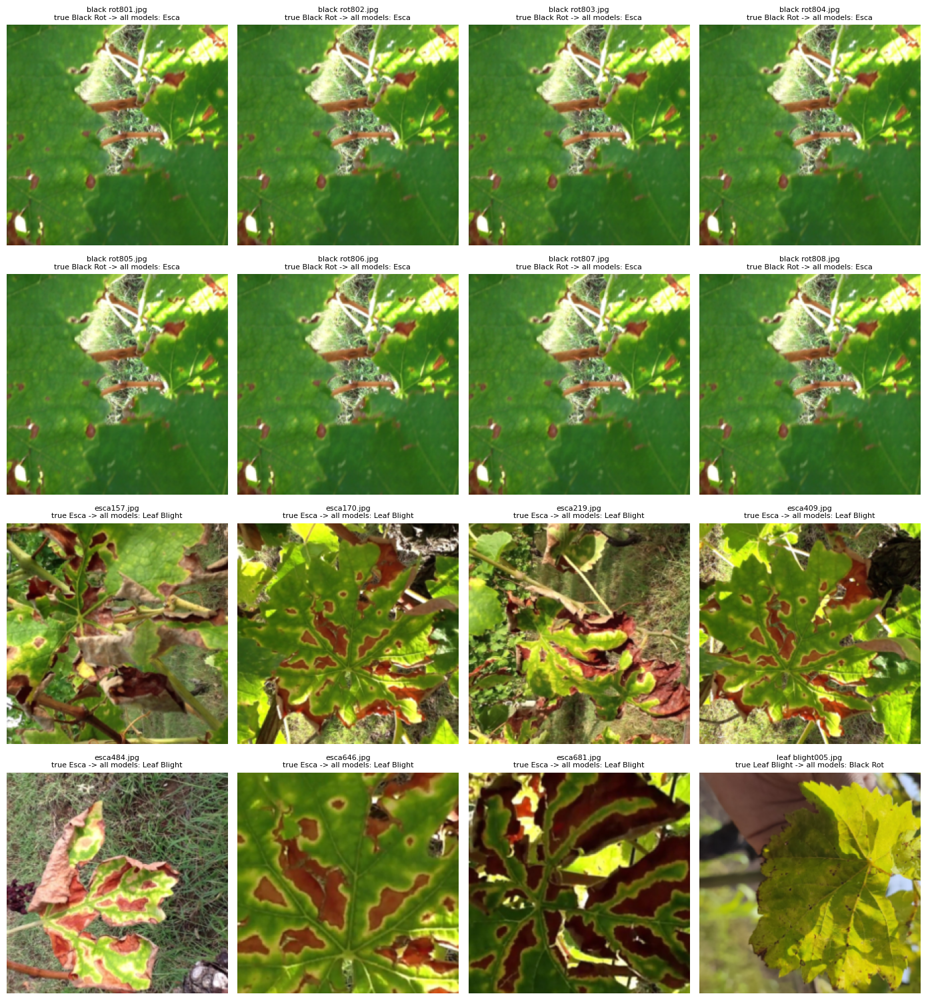

In [25]:
yt = y[idx["test"]]
preds = {m: predict_probs(TRAINED[m], idx["test"]).argmax(1) for m in MODELS}
all_wrong = np.all([preds[m] != yt for m in MODELS], axis=0)
same_wrong = all_wrong & np.all([preds[m] == preds[MODELS[0]] for m in MODELS], axis=0)
shared = np.where(same_wrong)[0]
print(f"{int(all_wrong.sum())} test images are wrong for all four models; {len(shared)} of them get the SAME wrong label from all four.")
shared_tab = pd.DataFrame({"filename": meta.filename.values[idx["test"]][shared],
                           "true": [CLASSES[k] for k in yt[shared]], "predicted": [CLASSES[k] for k in preds[MODELS[0]][shared]]})
display(shared_tab.groupby(["true", "predicted"]).size().rename("n"))
shared_tab.to_csv(OUT / "shared_errors.csv", index=False)

show = shared[:16]
nrows = max(1, int(np.ceil(len(show) / 4)))
fig, axes = plt.subplots(nrows, 4, figsize=(14, 3.8 * nrows))
for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
for ax, k in zip(np.atleast_1d(axes).ravel(), show):
    g = idx["test"][k]; ax.imshow(X[g])
    ax.set_title(f"{meta.filename[g]}\ntrue {CLASSES[yt[k]]} -> all models: {CLASSES[preds[MODELS[0]][k]]}", fontsize=8)
plt.tight_layout(); fig.savefig(OUT / "figures" / "shared_errors.png", dpi=120); plt.show()

**Cluster-aware evaluation.** The error galleries show the same photo many times (for example black rot801-808), so the test set holds far fewer independent scenes than images. This cell reports macro-F1 on the full test set, on one image per duplicate-cluster, and a 95% bootstrap interval that resamples whole clusters.

In [26]:

from sklearn.metrics import f1_score
yt = y[idx["test"]]
cl = meta.cluster.values[idx["test"]]
preds = {m: predict_probs(TRAINED[m], idx["test"]).argmax(1) for m in MODELS}
by_cl = [np.where(cl == c)[0] for c in np.unique(cl)]
print(f"test images: {len(yt)} | distinct duplicate-clusters in test: {len(by_cl)} | largest cluster: {max(len(b) for b in by_cl)}")

rng = np.random.RandomState(SEED)
first = np.array([rng.choice(b) for b in by_cl])                  # one random image per cluster
mf1 = lambda t, p: f1_score(t, p, average="macro", labels=range(NC), zero_division=0)
rows = []
for m in MODELS:
    p = preds[m]; boots = []
    for _ in range(1000):
        ii = np.concatenate([by_cl[k] for k in rng.randint(0, len(by_cl), len(by_cl))])
        boots.append(mf1(yt[ii], p[ii]))
    lo, hi = np.percentile(boots, [2.5, 97.5])
    rows.append(dict(model=m, f1_all_test_images=round(mf1(yt, p), 3), f1_one_per_cluster=round(mf1(yt[first], p[first]), 3),
                     ci95_low=round(lo, 3), ci95_high=round(hi, 3)))
cluster_eval = pd.DataFrame(rows).set_index("model")
display(cluster_eval); cluster_eval.to_csv(OUT / "cluster_aware_eval.csv")


test images: 487 | distinct duplicate-clusters in test: 344 | largest cluster: 8


,f1_all_test_images,f1_one_per_cluster,ci95_low,ci95_high
model,,,,
simple_cnn,0.841,0.795,0.775,0.892
resnet18,0.822,0.802,0.766,0.873
mobilenet_v3_small,0.811,0.767,0.746,0.860
convnext_tiny,0.838,0.846,0.779,0.887


**File-provenance probe.** Images with and without EXIF are split almost perfectly by class (no EXIF on any Healthy or Esca image), so the files may have been processed differently per class. This trains a random forest on file-level properties only (file size, JPEG quantization tables, EXIF/ICC present, progressive flag) - no pixels. A score far above the majority baseline means class can be guessed from how the file was produced, not from the leaf.

In [27]:

import os
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

def file_feats(p):
    im = Image.open(p); q = getattr(im, "quantization", None) or {}
    q0, q1 = np.array(q.get(0, [0])), np.array(q.get(1, [0]))
    return dict(size_kb=os.path.getsize(p) / 1024, q0_mean=q0.mean(), q0_first=q0[0], q1_mean=q1.mean(),
                has_exif=int("exif" in im.info), has_icc=int("icc_profile" in im.info), progressive=int(bool(im.info.get("progressive", 0))),
                n_qtables=len(q))
FF = pd.DataFrame([file_feats(p) for p in tqdm(meta.path, desc="file features")])
display(FF.groupby(meta.label.values).agg(["mean"]).round(2).T)

feats = {"all file features": list(FF.columns), "file size only": ["size_kb"], "JPEG quantization only": ["q0_mean", "q0_first", "q1_mean", "n_qtables"]}
rows = []
for name, cols in feats.items():
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(FF.loc[idx["train"], cols], y[idx["train"]])
    p = rf.predict(FF.loc[idx["test"], cols]); rows.append(dict(probe=name, test_acc=accuracy_score(y[idx["test"]], p), test_macro_f1=f1_score(y[idx["test"]], p, average="macro", labels=range(NC), zero_division=0)))
dm = DummyClassifier(strategy="most_frequent").fit(FF.loc[idx["train"]], y[idx["train"]]); p = dm.predict(FF.loc[idx["test"]])
rows.append(dict(probe="majority-class baseline", test_acc=accuracy_score(y[idx["test"]], p), test_macro_f1=f1_score(y[idx["test"]], p, average="macro", labels=range(NC), zero_division=0)))
prov = pd.DataFrame(rows); display(prov.round(3)); prov.to_csv(OUT / "provenance_probe.csv", index=False)


file features:   0%|          | 0/3477 [00:00<?, ?it/s]

,,Black Rot,Esca,Healthy,Leaf Blight
size_kb,mean,269.06,235.90,254.75,254.78
q0_mean,mean,11.50,11.50,11.50,11.50
q0_first,mean,3.00,3.00,3.00,3.00
q1_mean,mean,17.34,17.34,17.34,17.34
has_exif,mean,0.98,0.00,0.22,0.46
has_icc,mean,0.00,0.00,0.00,0.00
progressive,mean,0.00,0.00,0.00,0.00
n_qtables,mean,2.00,2.00,2.00,2.00


,probe,test_acc,test_macro_f1
0,all file features,0.343,0.332
1,file size only,0.265,0.234
2,JPEG quantization only,0.329,0.124
3,majority-class baseline,0.329,0.124


## 8. Shortcut probes (Midterm question 4)

Two simple, honest checks - neither is proof of shortcut learning, both are evidence:

1. **Colour-statistics probe** - a random forest on per-channel mean/std/histogram only (no shape or texture). Far above the majority-class baseline means colour/illumination alone carries class information.
2. **Border vs centre** - the same probe, and each trained network, on the outer frame only (mostly background) vs the centre only. If the border alone predicts class well, background/acquisition context is informative.
   The frame is not pure background (leaves can reach the edge), so describe it as "mostly background".

In [28]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

B = 32
border = np.ones((IMG, IMG), bool); border[B:-B, B:-B] = False
centre = ~border

def color_feats(Xs, mask=None):
    out = []
    for i in range(0, len(Xs), 256):
        a = Xs[i:i + 256].astype(np.float32) / 255
        a = a.reshape(len(a), -1, 3) if mask is None else a[:, mask, :]
        mu, sd = a.mean(1), a.std(1)
        hist = np.array([np.concatenate([np.histogram(r[:, c], bins=8, range=(0, 1))[0] / r.shape[0] for c in range(3)]) for r in a])
        out.append(np.hstack([mu, sd, hist]))
    return np.vstack(out)

rows = []
for tag_, mask in [("full image", None), ("border only (mostly background)", border), ("centre only (mostly leaf)", centre)]:
    F_ = color_feats(X, mask)
    rf = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(F_[idx["train"]], y[idx["train"]])
    pr = rf.predict_proba(F_[idx["test"]]); st = score(y[idx["test"]], pr)
    rows.append(dict(probe=tag_, test_acc=st["acc"], test_macro_f1=st["macro_f1"]))
dm = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(idx["train"]), 1)), y[idx["train"]])
pr = np.eye(NC)[dm.predict(np.zeros((len(idx["test"]), 1)))]; st = score(y[idx["test"]], pr)
rows.append(dict(probe="majority-class baseline", test_acc=st["acc"], test_macro_f1=st["macro_f1"]))
probe_df = pd.DataFrame(rows); display(probe_df.round(4)); probe_df.to_csv(OUT / "shortcut_probe_colour.csv", index=False)

,probe,test_acc,test_macro_f1
0,full image,0.6982,0.6463
1,border only (mostly background),0.6899,0.6286
2,centre only (mostly leaf),0.6920,0.6432
3,majority-class baseline,0.3285,0.1236


In [29]:
# Same idea with the trained networks: show only the border or only the centre (the rest is set to grey)
def masked(kind):
    Xt = X[idx["test"]].copy()
    if kind == "centre_only": Xt[:, border] = 124
    if kind == "border_only": Xt[:, centre] = 124
    return Xt
rows = []
for name in MODELS:
    for kind in ["original", "centre_only", "border_only"]:
        Xt = X[idx["test"]] if kind == "original" else masked(kind)
        st = score(y[idx["test"]], predict_probs(TRAINED[name], np.arange(len(Xt)), Xsrc=Xt))
        rows.append(dict(model=name, input=kind, acc=st["acc"], macro_f1=st["macro_f1"]))
mask_df = pd.DataFrame(rows); display(mask_df.pivot(index="model", columns="input", values="macro_f1").round(3).rename_axis("test macro-F1"))
mask_df.to_csv(OUT / "shortcut_probe_models.csv", index=False)

input,border_only,centre_only,original
test macro-F1,,,
convnext_tiny,0.802,0.861,0.838
mobilenet_v3_small,0.670,0.642,0.811
resnet18,0.485,0.793,0.822
simple_cnn,0.401,0.698,0.841


## 9. Export everything the submission needs

In [30]:
env = dict(python=sys.version.split()[0], platform=platform.platform(), seed=SEED, img_size=IMG, batch=BATCH,
           label_source=LABEL_SOURCE, dup_hash_threshold=DUP_T, split_file=SPLIT_FILE.name,
           numpy=np.__version__, pandas=pd.__version__)
try:
    import sklearn, torch, torchvision
    env.update(sklearn=sklearn.__version__, torch=torch.__version__, torchvision=torchvision.__version__,
               gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
except ImportError:
    pass
json.dump(dict(environment=env, hyperparameters=CFG), open(OUT / "config_and_environment.json", "w"), indent=2)
print(json.dumps(env, indent=2))
shutil.make_archive(str(WORK / "midterm_outputs"), "zip", OUT)
print("zip:", WORK / "midterm_outputs.zip", "(also in", OUT, ")")

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "seed": 42,
  "img_size": 224,
  "batch": 32,
  "label_source": "folder",
  "dup_hash_threshold": 2,
  "split_file": "iid_split_folder_seed42.csv",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "torch": "2.11.0+cu130",
  "torchvision": "0.26.0+cu130",
  "gpu": "Tesla T4"
}
zip: /content/work/midterm_outputs.zip (also in /content/drive/MyDrive/GVLiD_outputs_dedup )


## What to write in the report / slides (from the numbers above)

* **Q1 best model (IID):** the row with the highest test macro-F1 in `results_midterm.csv`; check the gap to the runner-up against the size of the test set (a few images can flip it).
* **Q2 trade-off:** compare macro-F1 with `params_M`, `GMACs`, `latency_ms_bs1`, `train_time_s`.
* **Q3 confusions:** the top off-diagonal cells in section 7, backed by the error gallery.
* **Q4 shortcuts:** section 8 tables plus examples you actually inspected. State clearly what the probes can and cannot show.
* **Limitations:** single run (one seed), untuned hyper-parameters, one test split, coarse duplicate check, metadata of unverified quality.